# Bollinger Band Mean Reversion: Backtest and Portfolio Optimisation

## Data Retrieval

The first step before beginning the analysis of the data is to select the ten stocks that will make up the portfolio. As a manager constructing this new equity portfolio, ten stocks were selected to balance sector diversification across Tech, Financials, Healthcare, Discretionary, Staples, Industrials, and Energy, as well as varied historical price dynamics. The selected stocks also need to have complete data over the 2020-2025 period. As such, the following portfolio selection was made:
1. MSFT (Microsoft Corp)
2. JPM (JPMorgan Chase & Co)
3. JNJ (Johnson & Johnson)
4. PFE (Pfizer Inc)
5. XOM (Exxon Mobil Corp)
6. NKE (Nike Inc)
7. KO (Coca-Cola Co)
8. PYPL (PayPal Holdings Inc)
9. INTC (Intel Corp)
10. BA (Boeing Co)

The portfolio aims to prioritise sector diversification to reduce idiosyncratic risk: the selected stocks span technology (MSFT, INTC), financials (JPM, PYPL), healthcare (JNJ, PFE), energy (XOM), consumer discretionary (NKE), consumer staples (KO), and industrials (BA). Furthermore, MSFT, JPM, JNJ, XOM, and KO were selected as established, large-cap stocks with sustained long-term uptrends, providing a baseline against which buy-and-hold could be expected to perform strongly. PYPL, INTC, NKE, and BA were selected for their more volatile or range-bound price histories over the period, driven by company-specific events, providing genuine candidates for the mean reversion strategy to outperform buy-and-hold. All ten stocks are large, liquid, US-listed companies with complete daily trading data over the 2020-2025 period.

Having selected the portfolio of ten stocks, the first step to the analysis is to pull data for each stock across 2020-2025 from Yahoo! Finance and load it into the `pandas`data frame. We will also load all necessary inputs for visualisation at this stage to have everything loaded from the beginning.

In [282]:
import sys
!{sys.executable} -m pip install yfinance

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [283]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt

The code below loads daily price data for all ten stocks into a single data frame, from 1 January 2020 to 31 December 2025. Setting the end date to 1 January 2026 ensures the full data range, as the `yfinance` parameter is exclusive and will then only display data through to 31 December 2025. Moreover, data for 1 January across the period is unavailable as 1 January is not a trading day in US markets, so the full period displays from 2 January 2020 to 31 December 2025.

The `tickers` list defines the ten stocks selected, and `yf.download()` retrieves their historical data and combines them into a single structure. Running `data` allows for visualisation of the results in table format.

In [284]:
tickers = ['MSFT', 'JPM', 'JNJ', 'PFE', 'XOM', 'NKE', 'KO', 'PYPL', 'INTC', 'BA']
data = yf.download(tickers, start='2020-01-01', end='2026-01-01')
data

[*********************100%***********************]  10 of 10 completed


Price            Close                                                \
Ticker              BA       INTC         JNJ         JPM         KO   
Date                                                                   
2020-01-02  331.348572  53.666470  121.936935  118.430336  45.141262   
2020-01-03  330.791901  53.013714  120.525185  116.867508  44.894989   
2020-01-06  331.766083  52.863762  120.374863  116.774559  44.878574   
2020-01-07  335.285156  51.981667  121.109947  114.789291  44.533791   
2020-01-08  329.410095  52.016960  121.093262  115.684776  44.615879   
...                ...        ...         ...         ...        ...   
2025-12-24  218.160004  36.160000  205.499420  326.023376  69.184540   
2025-12-26  216.440002  36.200001  205.351059  324.775421  68.947716   
2025-12-29  217.250000  36.680000  205.281830  320.655182  69.233879   
2025-12-30  218.500000  37.299999  204.638962  320.328339  69.145073   
2025-12-31  217.119995  36.900002  204.678528  319.139801  68.987183   

Price                                                                 ...  \
Ticker            MSFT        NKE        PFE        PYPL         XOM  ...   
Date                                                                  ...   
2020-01-02  151.829529  92.821114  27.048363  109.799088   52.947029  ...   
2020-01-03  149.938995  92.566788  26.903240  107.826172   52.521362  ...   
2020-01-06  150.326584  92.485062  26.868692  109.224068   52.924625  ...   
2020-01-07  148.955917  92.439651  26.778852  108.728355   52.491482  ...   
2020-01-08  151.328568  92.230759  26.993080  110.859901   51.699909  ...   
...                ...        ...        ...         ...         ...  ...   
2025-12-24  485.856323  59.075760  24.217873   59.662098  117.632187  ...   
2025-12-26  485.547729  59.991436  24.275923   59.592537  117.523659  ...   
2025-12-29  484.940430  60.267124  24.188845   59.115559  118.924744  ...   
2025-12-30  485.318756  60.247429  24.179169   58.728008  119.378616  ...   
2025-12-31  481.475861  62.728611  24.092089   58.012543  118.737274  ...   

Price        Volume                                                   \
Ticker           BA      INTC      JNJ       JPM        KO      MSFT   
Date                                                                   
2020-01-02  4544400  18056000  5777000  10803700  11867700  22622100   
2020-01-03  3875900  15293900  5752400  10386800  11354500  21116200   
2020-01-06  5355000  17755200  7731300  10259000  14698300  20813700   
2020-01-07  9898600  21876100  7382900  10531300   9973900  21634100   
2020-01-08  8239200  23133500  6605800   9695300  10676000  27746500   
...             ...       ...      ...       ...       ...       ...   
2025-12-24  2943500  37443800  2376500   4289300   4515300   5855900   
2025-12-26  2801500  28779400  2316700   4158300   5711400   8842200   
2025-12-29  5292000  38062300  4348900   8635300   9686900  10893400   
2025-12-30  5653500  61935300  3937400   7904300   8610900  13944500   
2025-12-31  5563000  51524700  4083800   5048500   8127800  15601600   

Price                                               
Ticker           NKE       PFE      PYPL       XOM  
Date                                                
2020-01-02   5644100  16514072   7418800  12456400  
2020-01-03   4541800  14922848   7098300  17386900  
2020-01-06   4612400  15771951   6764500  20081900  
2020-01-07   6719900  20108107   6898700  17387700  
2020-01-08   4942200  16403507   8293600  15137700  
...              ...       ...       ...       ...  
2025-12-24  36073300  19328500   5491700   6137400  
2025-12-26  22303600  21617800   7537800   8066100  
2025-12-29  18062100  33067700  12910100  14782500  
2025-12-30  13507800  28821700  11277900  11150500  
2025-12-31  35457400  29409200  13027300  10559900  

[1508 rows x 50 columns]

## Data Cleaning

Before proceeding with the analysis, an important step is cleaning the data to check for inconsistencies that could distort the results of the trading strategy. This involves checking for missing values or duplicates, confirming correct date range, ordering, and completeness, and ensuring trading day alignment across all ten stocks. Where any issues are identified, the chosen method of resolution is explained and justified based on its suitability for financial time series data.

### Closing Prices

The data cleaning is focused on closing prices, as this is the basis for subsequent analysis, including return calculations, Bollinger Bands, and portfolio optimisation. Open, High, Low, and Volume data are not used directly in the analysis and are excluded from the cleaning process. 

Using closing price data, we first extract closing prices for all ten stocks into their own wide data frame to visualise them in table format. From there, the main data cleaning checks are as follows:
- `.index.is_monotonic_increasing()` - confirms dates are in chronological order (should yield `True` if this holds)
- `.duplicated().sum()` - counts duplicated rows (should yield 0 if there are no duplicate values)
- `.isnull().sum()` - counts missing values per stock (should yield 0 if there are no missing values)
- `.dtypes` - confirms all columns are `float64`
- `.index.min()` and `.index.max()` confirm the coverage of the full 2020-2025 period, and `print(len(close))` gives us the total number of trading days.

In [285]:
close = data["Close"]
close

Ticker,BA,INTC,JNJ,JPM,KO,MSFT,NKE,PFE,PYPL,XOM
Date,,,,,,,,,,
2020-01-02,331.348572,53.666470,121.936935,118.430336,45.141262,151.829529,92.821114,27.048363,109.799088,52.947029
2020-01-03,330.791901,53.013714,120.525185,116.867508,44.894989,149.938995,92.566788,26.903240,107.826172,52.521362
2020-01-06,331.766083,52.863762,120.374863,116.774559,44.878574,150.326584,92.485062,26.868692,109.224068,52.924625
2020-01-07,335.285156,51.981667,121.109947,114.789291,44.533791,148.955917,92.439651,26.778852,108.728355,52.491482
2020-01-08,329.410095,52.016960,121.093262,115.684776,44.615879,151.328568,92.230759,26.993080,110.859901,51.699909
...,...,...,...,...,...,...,...,...,...,...
2025-12-24,218.160004,36.160000,205.499420,326.023376,69.184540,485.856323,59.075760,24.217873,59.662098,117.632187
2025-12-26,216.440002,36.200001,205.351059,324.775421,68.947716,485.547729,59.991436,24.275923,59.592537,117.523659
2025-12-29,217.250000,36.680000,205.281830,320.655182,69.233879,484.940430,60.267124,24.188845,59.115559,118.924744


In [286]:
close.index.is_monotonic_increasing

True

In [287]:
close.duplicated().sum()

np.int64(0)

In [288]:
close.isnull().sum()

Ticker
BA      0
INTC    0
JNJ     0
JPM     0
KO      0
MSFT    0
NKE     0
PFE     0
PYPL    0
XOM     0
dtype: int64

In [289]:
close.dtypes

Ticker
BA      float64
INTC    float64
JNJ     float64
JPM     float64
KO      float64
MSFT    float64
NKE     float64
PFE     float64
PYPL    float64
XOM     float64
dtype: object

In [290]:
print(close.index.min(), close.index.max())
print(len(close))

2020-01-02 00:00:00 2025-12-31 00:00:00
1508


In [291]:
close.index.max()

Timestamp('2025-12-31 00:00:00')

Having run the necessary data cleaning steps, we have confirmed there are no missing or duplicate values, the data is the correct type, and the date range is correctly running from 2 January 2020 to 31 December 2025. 

The dataset contains 1508 trading days between these dates, which is consistent with the expected range of approximately 250-253 trading days per year over the period, and accounts for weekends, standard NYSE/NASDAQ holidays, and occasional one-off closures (such as the market closure on 9 January 2025 to honour the passing of former president Jimmy Carter) ([Intercontinental Exchange](https://ir.theice.com/press/news-details/2024/The-New-York-Stock-Exchange-Will-Close-Markets-on-January-9-to-Honor-the-Passing-of-Former-President-Jimmy-Carter-on-National-Day-of-Mourning/default.aspx)).

## Data Exploration

This next section provides an initial view of the closing price data, presenting the head and tail of the data frame to confirm the structure and range of the dataset. Having done this, we will then produce a single plot of all ten stocks over the period to visualise differences in price level, growth, and volatility across the portfolio. 

In [292]:
close.head()

Ticker,BA,INTC,JNJ,JPM,KO,MSFT,NKE,PFE,PYPL,XOM
Date,,,,,,,,,,
2020-01-02,331.348572,53.666470,121.936935,118.430336,45.141262,151.829529,92.821114,27.048363,109.799088,52.947029
2020-01-03,330.791901,53.013714,120.525185,116.867508,44.894989,149.938995,92.566788,26.903240,107.826172,52.521362
2020-01-06,331.766083,52.863762,120.374863,116.774559,44.878574,150.326584,92.485062,26.868692,109.224068,52.924625
2020-01-07,335.285156,51.981667,121.109947,114.789291,44.533791,148.955917,92.439651,26.778852,108.728355,52.491482
2020-01-08,329.410095,52.016960,121.093262,115.684776,44.615879,151.328568,92.230759,26.993080,110.859901,51.699909


In [293]:
close.tail()

Ticker,BA,INTC,JNJ,JPM,KO,MSFT,NKE,PFE,PYPL,XOM
Date,,,,,,,,,,
2025-12-24,218.160004,36.160000,205.499420,326.023376,69.184540,485.856323,59.075760,24.217873,59.662098,117.632187
2025-12-26,216.440002,36.200001,205.351059,324.775421,68.947716,485.547729,59.991436,24.275923,59.592537,117.523659
2025-12-29,217.250000,36.680000,205.281830,320.655182,69.233879,484.940430,60.267124,24.188845,59.115559,118.924744
2025-12-30,218.500000,37.299999,204.638962,320.328339,69.145073,485.318756,60.247429,24.179169,58.728008,119.378616
2025-12-31,217.119995,36.900002,204.678528,319.139801,68.987183,481.475861,62.728611,24.092089,58.012543,118.737274


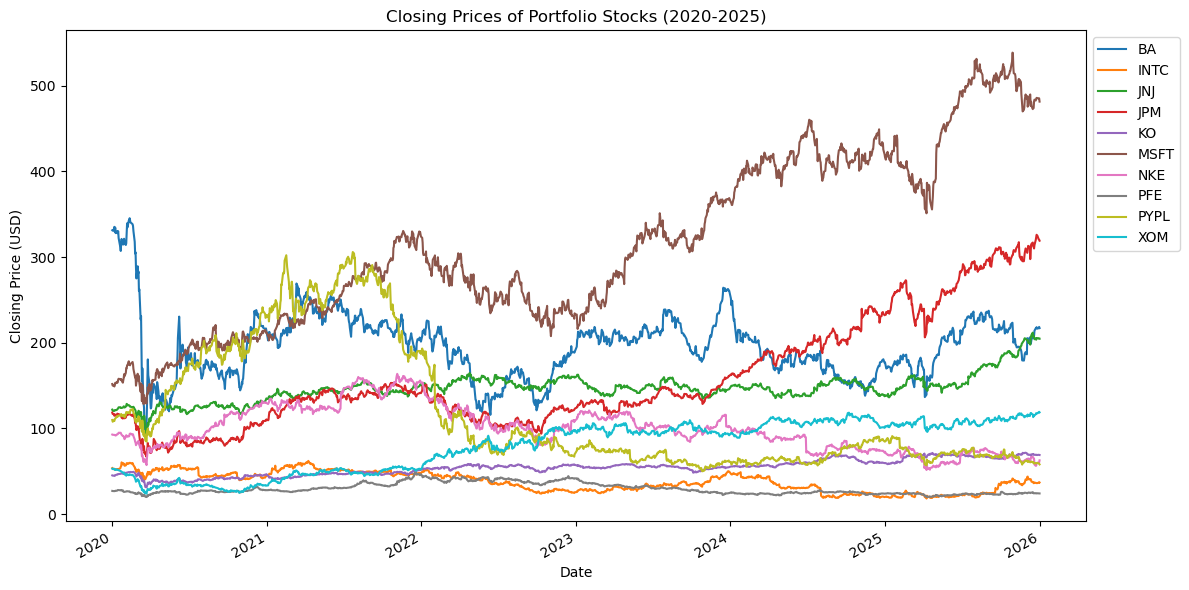

In [294]:
close.plot(figsize=(12, 6), title="Closing Prices of Portfolio Stocks (2020-2025)")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend(bbox_to_anchor=(1,1))
plt.tight_layout()
plt.show()

### Commentary

The plot reveals clear differences in both price level and price behaviour across the portfolio. Microsoft (MSFT) trades at a materially higher price level than the rest of the portfolio and exhibits a strong, sustained upward trend over the six-year period, consistent with its position as one of the largest companies globally by market capitalisation and continued growth in its cloud and software businesses.

Boeing (BA) and PayPal (PYPL), by contrast, display genuine volatility: large, sustained price swings without a clear long-term directional trend. Boeing's price history reflects company-specific shocks, including the 2019 737 MAX grounding, the collapse in air travel demand during the COVID-19 pandemic, and renewed production and safety issues through 2023-2024. PayPal rose sharply during the pandemic-driven e-commerce boom before falling by close to 80% from its 2021 peak, reflecting slowing growth and margin pressure once pandemic-era demand normalised.

The remaining stocks (JPM, JNJ, PFE, XOM, NKE, KO, INTC) display more modest price ranges in absolute terms, though this partly reflects the shared price axis; their relative performance and volatility are assessed more meaningfully using daily returns later in this notebook.

## Trading Strategy

This next section will implement and back test a Bollinger Band mean reversion strategy for each stock to leverage the tendency of asset prices to revert to their mean. The first step is to calculate Bollinger Bands on closing prices, where the middle band is the 20-day simple moving average and the upper and lower bands are 2 standard deviations above and below the middle band, respectively. 

Trading signals are generated based on the position of the closing price relative to these bands; a buy signal is triggered when the price falls below the lower band, on the expectation that the price will revert upward toward the mean. Conversely, a sell (short) signal is triggered when the price rises above the upper band, on the expectation that the price will revert downward toward the mean. Positions are exited once the price reverts back to the middle band, at which point the mean reversion is considered to have occurred.

### *MSFT Bollinger Bands and Mean Reversion Strategy*

### Calculating the 20-day simple moving average (middle band) and rolling standard deviation

The first step is calculating the 20-day simple moving average (which will comprise the middle band) using the `.rolling().mean()` function, and the rolling standard deviation for the upper and lower bands. The code below applies to the Microsoft (MSFT) stock, but will be repeated for all stocks in the portfolio.

In [295]:
df_msft = pd.DataFrame(index=close.index)
df_msft["Close"] = close["MSFT"]

window = 20
df_msft["SMA"] = df_msft["Close"].rolling(window=window).mean()
df_msft["Dev"] = df_msft["Close"].rolling(window=window).std()
df_msft["UpperBand"] = df_msft["SMA"] + 2 * df_msft["Dev"]
df_msft["LowerBand"] = df_msft["SMA"] - 2 * df_msft["Dev"]

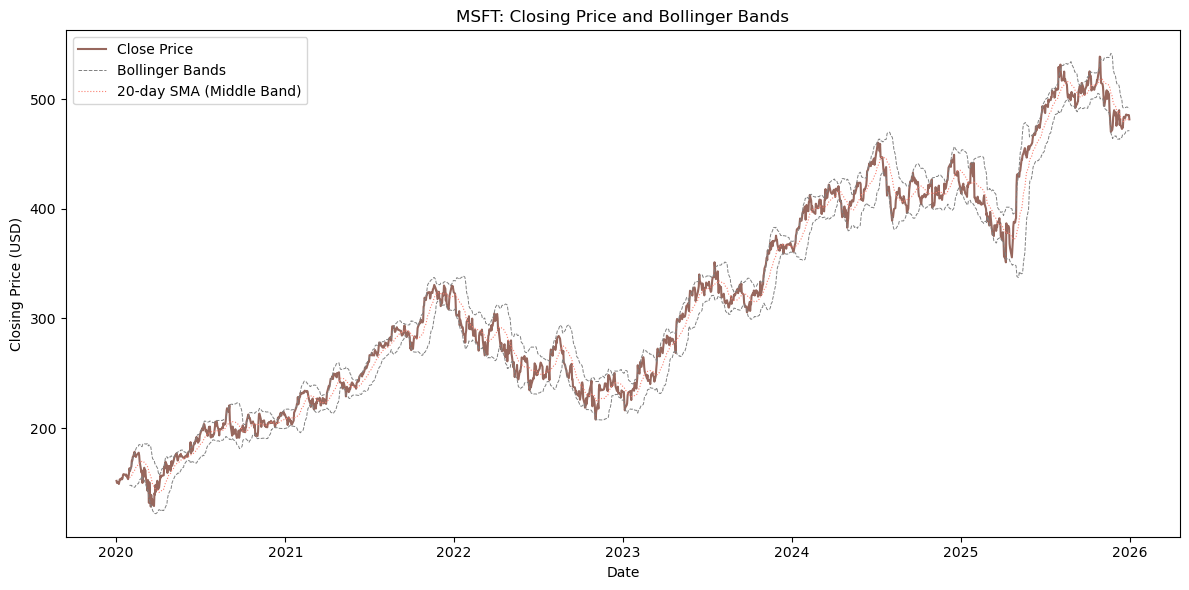

In [296]:
plt.figure(figsize=(12, 6))

plt.plot(df_msft["Close"], color="#8c564b", label="Close Price", alpha=0.9)
plt.plot(df_msft["UpperBand"], color="grey", linewidth=0.7, linestyle="--", label="Bollinger Bands")
plt.plot(df_msft["LowerBand"], color="grey", linewidth=0.7, linestyle="--")
plt.plot(df_msft["SMA"], color="salmon", linewidth=0.8, linestyle=":", label="20-day SMA (Middle Band)")

plt.title("MSFT: Closing Price and Bollinger Bands")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.tight_layout()
plt.show()

### Generating entry signals

A signal of 1 (buy) is assigned wherever the closing price falls below the lower band, and a signal of -1 (sell/short) is assigned wherever it rises above the upper band. All other days default to zero, indicating no signal. This reflects Step 2 of the strategy, as each day's signal is based purely on that day's closing price relative to the bands, independent of any position currently held.

In [297]:
df_msft["Signal"] = 0
df_msft.loc[df_msft["Close"] < df_msft["LowerBand"], "Signal"] = 1
df_msft.loc[df_msft["Close"] > df_msft["UpperBand"], "Signal"] = -1

### Generating positions

Unlike the signal, which is a same-day judgement, the position must account for whether a trade is already open from a previous day, and this is tracked using a loop. If no position is currently held, a new position is opened according to that day's signal. If a long position is already held, it remains open until the price rises back to the middle band (the exit condition); if a short position is held, it remains open until the price falls back to the middle band. The position is then shifted forward by one day to avoid look-ahead bias, since a position formed using a given day's closing price could not have been acted upon until the following trading day.

In [298]:
position = pd.Series(0, index=df_msft.index)

for i in range(1, len(df_msft)):
    prev_position = position.iloc[i-1]
    price_today = df_msft["Close"].iloc[i]
    mid_today = df_msft["SMA"].iloc[i]

    if prev_position == 0:
        position.iloc[i] = df_msft["Signal"].iloc[i]
    elif prev_position == 1:
        position.iloc[i] = 0 if price_today >= mid_today else 1
    elif prev_position == -1:
        position.iloc[i] = 0 if price_today <= mid_today else -1

df_msft["Position"] = position
df_msft["PositionShifted"] = df_msft["Position"].shift(1) 

### Calculating simple daily returns (buy-and-hold basis)

Simple daily returns are calculated as the percentage change in closing price from one day to the next, representing the return an investor would have earned from a buy-and-hold approach.

In [299]:
df_msft["MarketDaily"] = df_msft["Close"].pct_change()

### Calculating strategy daily returns

Strategy daily returns are calculated by multiplying the shifted position by the simple daily return. Using the previous day's position ensures that a position formed using today's closing price only begins generating returns from the following trading day, consistent with the look-ahead bias adjustment made above.

In [300]:
df_msft["StrategyDaily"] = df_msft["PositionShifted"] * df_msft["MarketDaily"]

### Calculating cumulative returns

Cumulative returns are calculated by compounding daily returns over time, converting the series of daily percentage changes into a single running total return. This allows the strategy's overall performance to be compared directly against a buy-and-hold approach over the full period.

In [301]:
df_msft["MarketReturn"] = (1 + df_msft["MarketDaily"]).cumprod() - 1
df_msft["StrategyReturn"] = (1 + df_msft["StrategyDaily"].fillna(0)).cumprod() - 1

### Displaying end-of-period cumulative returns

The final value in each cumulative return series represents the total return achieved by each approach (strategy vs. buy-and-hold) over the entire backtest period, providing a single, directly comparable figure for evaluating performance.

In [302]:
print(f"MSFT Strategy cumulative return: {df_msft['StrategyReturn'].iloc[-1]:.2%}")
print(f"MSFT Buy-and-Hold cumulative return: {df_msft['MarketReturn'].iloc[-1]:.2%}")

MSFT Strategy cumulative return: 35.02%
MSFT Buy-and-Hold cumulative return: 217.12%


### Plotting strategy vs. buy-and-hold

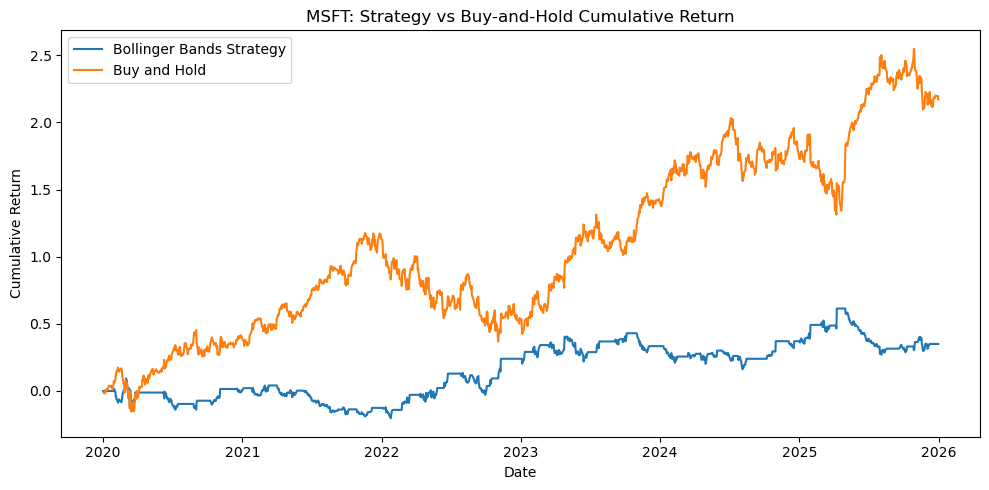

In [303]:
plt.figure(figsize=(10, 5))
plt.plot(df_msft["StrategyReturn"], label="Bollinger Bands Strategy")
plt.plot(df_msft["MarketReturn"], label="Buy and Hold")
plt.title("MSFT: Strategy vs Buy-and-Hold Cumulative Return")
plt.xlabel("Date")
plt.ylabel("Cumulative Return")
plt.legend()
plt.tight_layout()
plt.show()

MSFT is a strong, persistent trending stock and is not particularly range-bound or choppy. This trend is supported by sustained growth in its Intelligent Cloud segment, as Azure revenue grew 33-40% year-on-year across multiple quarters during the period of observation, with Microsoft Cloud revenue reaching $168.9bn in FY2025. This represents a 23% increase relative to the previous year ([Microsoft, 2025](https://www.microsoft.com/investor/reports/ar25/index.html)). 

In this case, the mean reversion strategy essentially bets against sustained trends, as each time MSFT's price rose materially above its 20-day average, the strategy interpreted this as overbought and entered a short position. However, because the price continued climbing, this strategy was overall less effective than buy-and-hold, which was able to capture the entirety of this drift. Overall, buy-and-hold returned 217% over the period compared to the mean reversion strategy's 35%. 

### *JPM Bollinger Bands and Mean Reversion Strategy*

For JPM and all subsequent stocks, instead of running the calculations and building the graphs manually, a function will be employed to run the Bollinger strategy. This function will calculate Bollinger bands, signals, positions, and returns for a given stock, as well as plotting both the bands and cumulative return comparison. The detailed function can be seen below, with application to JPM in this section.

In [304]:
def run_bollinger_strategy(ticker, window=20):
    """Calculates Bollinger Bands, signals, positions and daily returns for a given stock,
    storing all values as columns on a DataFrame, and plotting the bands immediately after
    Step 1, and the cumulative return comparison at the end."""

    df = pd.DataFrame(index=close.index)
    df["Close"] = close[ticker]
    ticker_color = plt.rcParams['axes.prop_cycle'].by_key()['color'][close.columns.get_loc(ticker)]

    # Step 1: Bollinger Bands
    df["SMA"] = df["Close"].rolling(window=window).mean()
    df["Dev"] = df["Close"].rolling(window=window).std()
    df["UpperBand"] = df["SMA"] + 2 * df["Dev"]
    df["LowerBand"] = df["SMA"] - 2 * df["Dev"]

    # Bands plot, shown immediately after Step 1
    plt.figure(figsize=(12, 6))
    plt.plot(df["Close"], color=ticker_color, label="Close Price", alpha=0.9)
    plt.plot(df["UpperBand"], color="grey", linewidth=0.7, linestyle="--", label="Bollinger Bands")
    plt.plot(df["LowerBand"], color="grey", linewidth=0.7, linestyle="--")
    plt.plot(df["SMA"], color="salmon", linewidth=0.8, linestyle=":", label="20-day SMA (Middle Band)")
    plt.title(f"{ticker}: Closing Price and Bollinger Bands")
    plt.xlabel("Date")
    plt.ylabel("Closing Price (USD)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Step 2: Entry signals
    df["Signal"] = 0
    df.loc[df["Close"] < df["LowerBand"], "Signal"] = 1
    df.loc[df["Close"] > df["UpperBand"], "Signal"] = -1

    # Step 3: Positions
    position = pd.Series(0, index=df.index)
    for i in range(1, len(df)):
        prev_position = position.iloc[i-1]
        price_today = df["Close"].iloc[i]
        mid_today = df["SMA"].iloc[i]
        if prev_position == 0:
            position.iloc[i] = df["Signal"].iloc[i]
        elif prev_position == 1:
            position.iloc[i] = 0 if price_today >= mid_today else 1
        elif prev_position == -1:
            position.iloc[i] = 0 if price_today <= mid_today else -1
    df["Position"] = position
    df["PositionShifted"] = df["Position"].shift(1)

    # Steps 4-6: Returns
    df["MarketDaily"] = df["Close"].pct_change()
    df["StrategyDaily"] = df["PositionShifted"] * df["MarketDaily"]
    df["MarketReturn"] = (1 + df["MarketDaily"]).cumprod() - 1
    df["StrategyReturn"] = (1 + df["StrategyDaily"].fillna(0)).cumprod() - 1

    # Step 7: Print results
    print(f"{ticker} Strategy cumulative return: {df['StrategyReturn'].iloc[-1]:.2%}")
    print(f"{ticker} Buy-and-Hold cumulative return: {df['MarketReturn'].iloc[-1]:.2%}")

    # Step 8: Plot cumulative return comparison
    plt.figure(figsize=(10, 5))
    plt.plot(df["StrategyReturn"], label="Bollinger Bands Strategy")
    plt.plot(df["MarketReturn"], label="Buy and Hold")
    plt.title(f"{ticker}: Strategy vs Buy-and-Hold Cumulative Return")
    plt.xlabel("Date")
    plt.ylabel("Cumulative Return")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return df["StrategyDaily"], df["MarketDaily"]

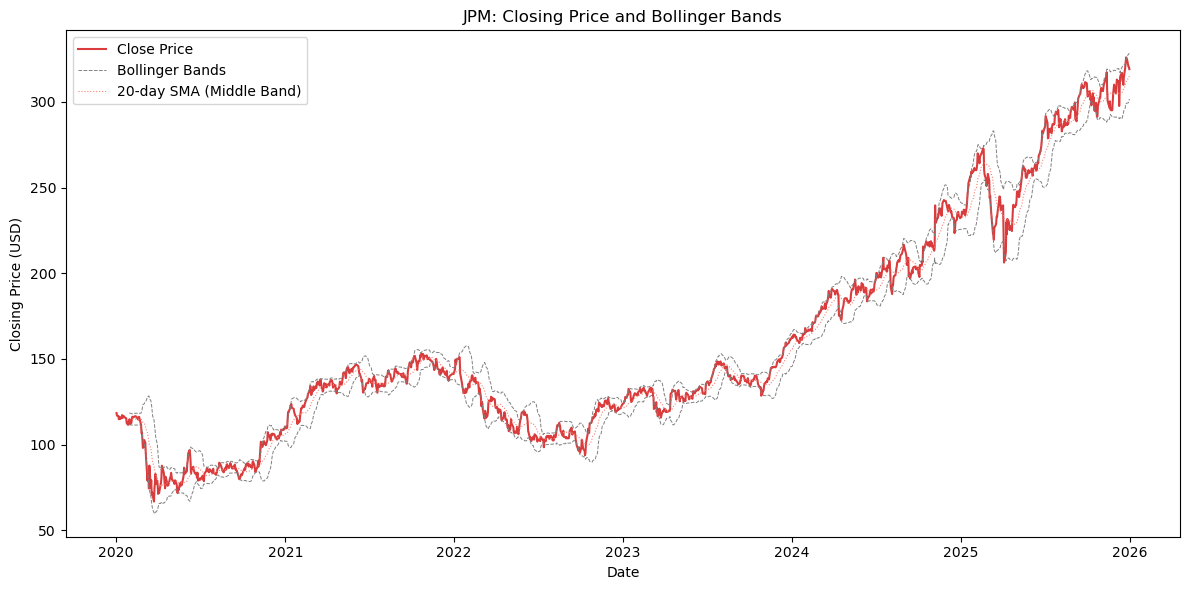

JPM Strategy cumulative return: 19.43%
JPM Buy-and-Hold cumulative return: 169.47%


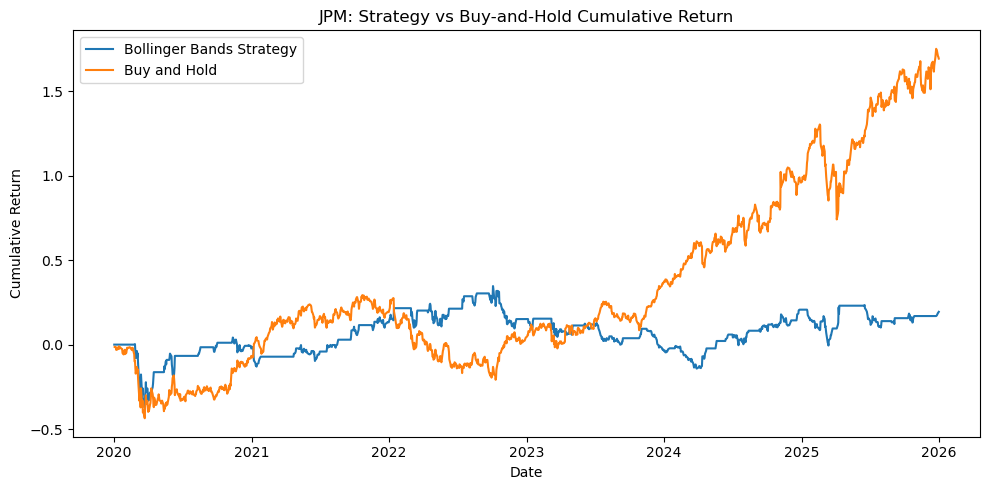

In [305]:
jpm_strategy, jpm_bh = run_bollinger_strategy("JPM")

JPM's upward trend has been supported by rising interest rates from 2022 onward which boosted the bank's profitability via higher net interest income. JPMorgan reported a 44% jump in net interest income in Q2 2023 as the bank benefitted from higher rates and loan growth ([CNBC, 2023](https://www.cnbc.com/2023/07/14/jpmorgan-chase-jpm-earnings-2q-2023.html)). Similarly to MSFT, the mean reversion strategy's repeated short signals worked against this sustained uptrend, resulting in underperformance relative to buy-and-hold.

### *JNJ Bollinger Bands and Mean Reversion Strategy*

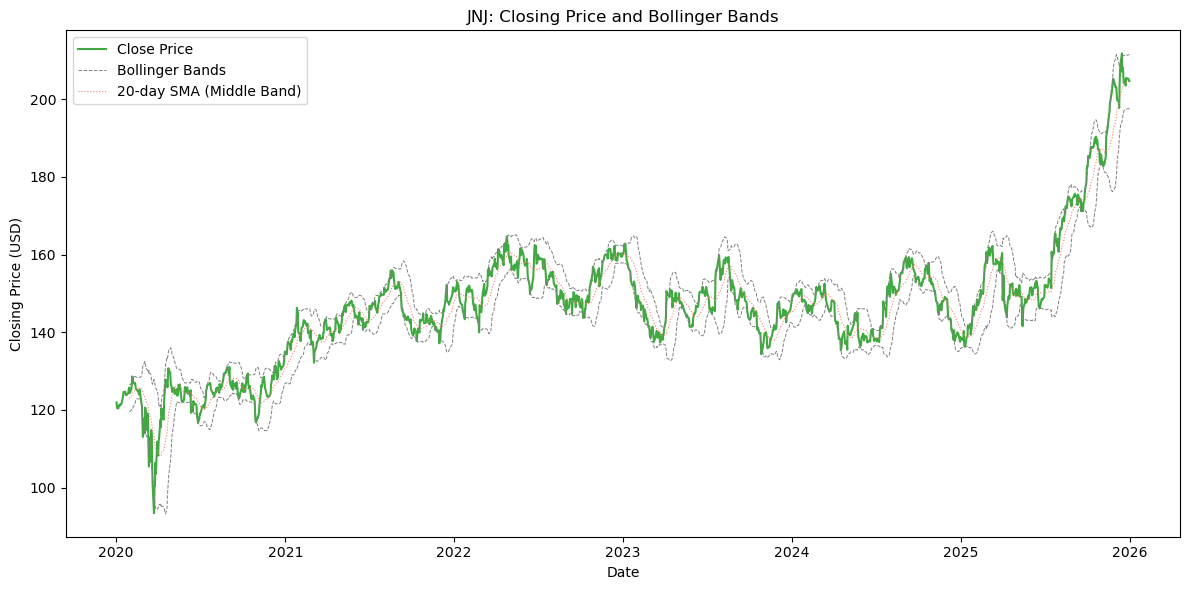

JNJ Strategy cumulative return: -8.83%
JNJ Buy-and-Hold cumulative return: 67.86%


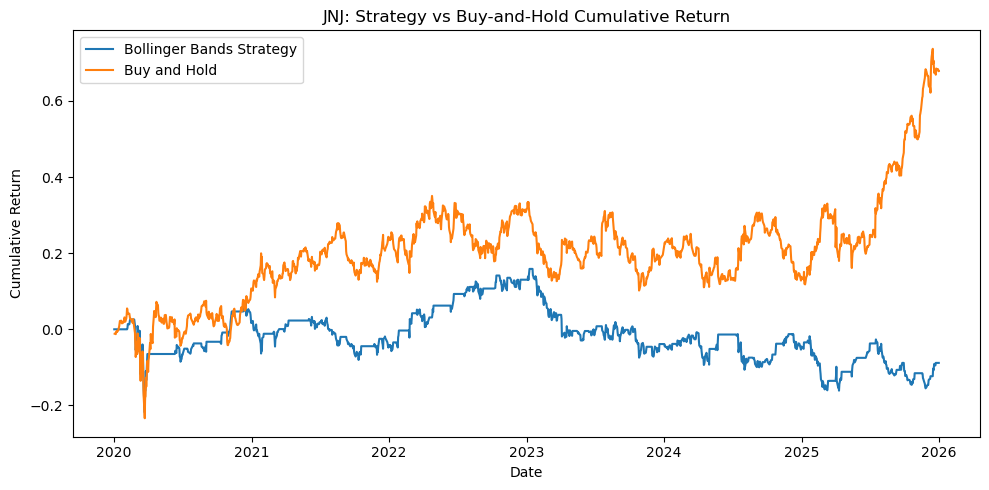

In [306]:
jnj_strategy, jnj_bh = run_bollinger_strategy("JNJ")

JNJ has a steadier and lower-volatility trend compared to MSFT and JPM, which is consistent with its status as a defensive healthcare stock. Although its growth has been comparatively modest, the stock has not experienced the kind of sustained drawdown which would favour a mean reversion approach. As such, buy-and-hold again outperformed the mean reversion strategy here.

### *PFE Bollinger Bands and Mean Reversion Strategy*

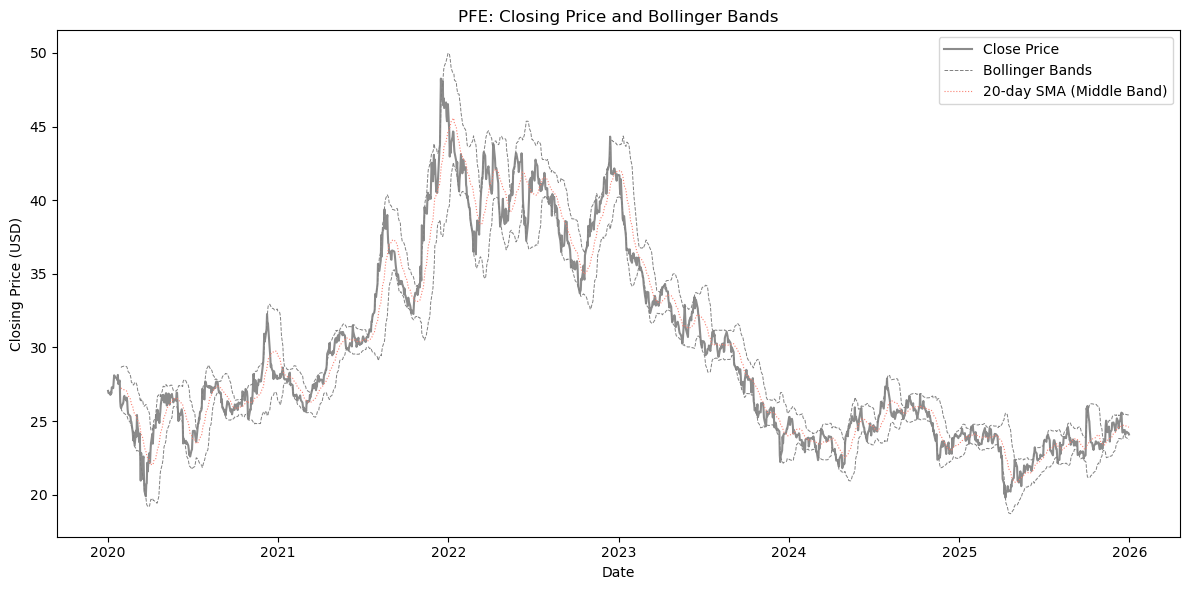

PFE Strategy cumulative return: -15.46%
PFE Buy-and-Hold cumulative return: -10.93%


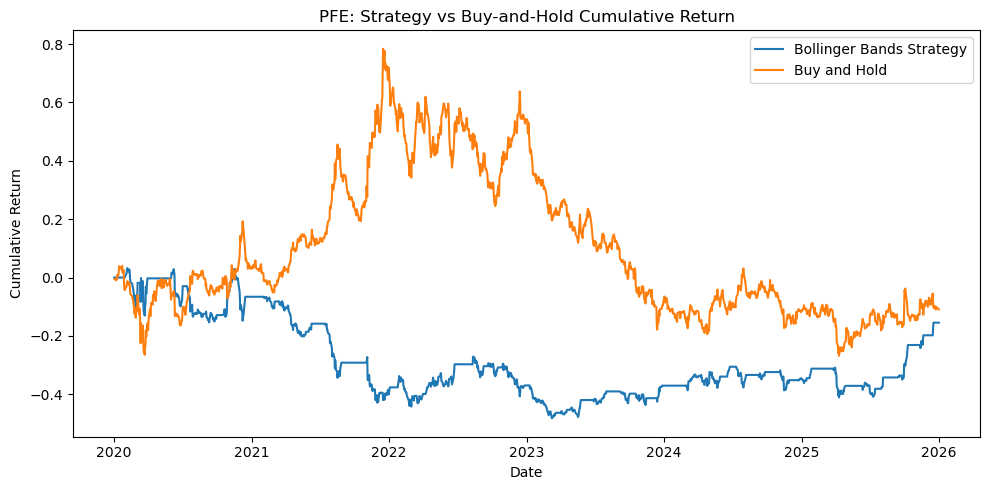

In [307]:
pfe_strategy, pfe_bh = run_bollinger_strategy("PFE")

PFE has a starkly different shape compared to JNJ. Its price peaked at \$61.25 on 16 December 2021, driven by the success of its COVID-19 vaccine. Sales of the vaccine fell from almost 38bn in 2022 to an anticipated 14bn in 2023 (USD) as the demand from the pandemic normalised ([BioPharma Dive, 2023](https://www.biopharmadive.com/news/pfizer-covid-comirnaty-paxlovid-sales-guidance-2023/641604/)). This drove a prolonged decline through to 2025, but despite that, buy-and-hold still outperformed the mean reversion strategy, suggesting the stock's fall was too persistent and directional for the strategy's mechanism to fully offset the overall loss.

### *XOM Bollinger Bands and Mean Reversion Strategy*

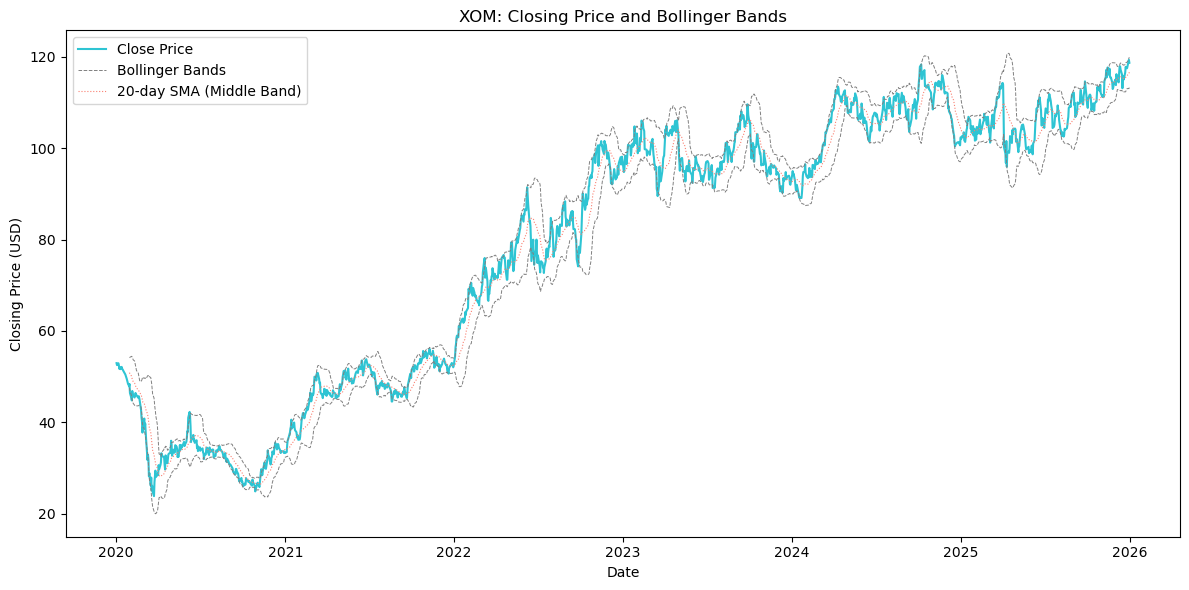

XOM Strategy cumulative return: 18.12%
XOM Buy-and-Hold cumulative return: 124.26%


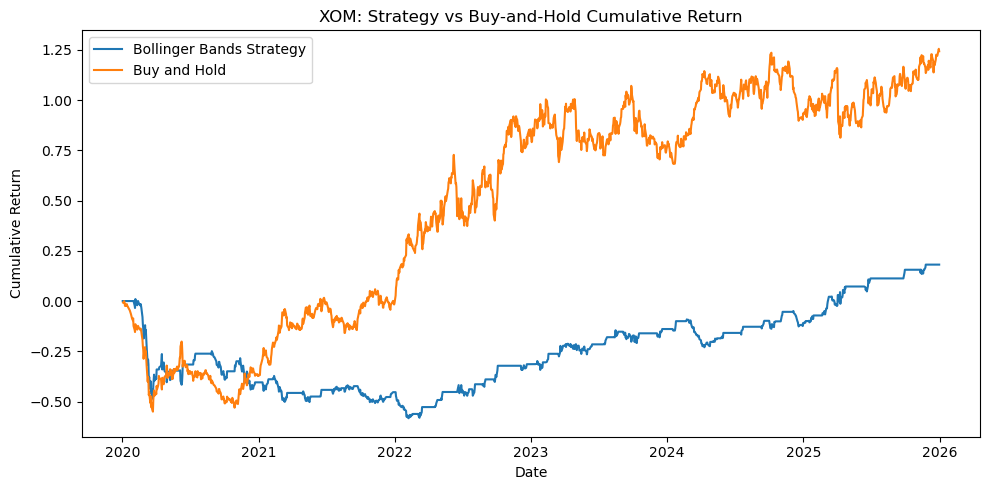

In [308]:
xom_strategy, xom_bh = run_bollinger_strategy("XOM")

XOM fell over 40% in 2020 as COVID-19 caused oil demand to decline, which forced the company to cut capital spending and take on additional debt to maintain its dividend ([The Motley Fool, 2021](https://www.fool.com/investing/2021/01/05/why-exxon-mobil-stock-lost-more-than-40-in-2020/)). The stock recovered after this when energy prices rose through 2021-2022 due to post-pandemic recovery and supply constraints, consistent with the sustained upward trend visible from 2022 onward in the chart above. Similarly to other trend-following stocks in the portfolio, buy-and-hold outperformed the mean reversion strategy over the full period.

### *NKE Bollinger Bands and Mean Reversion Strategy*

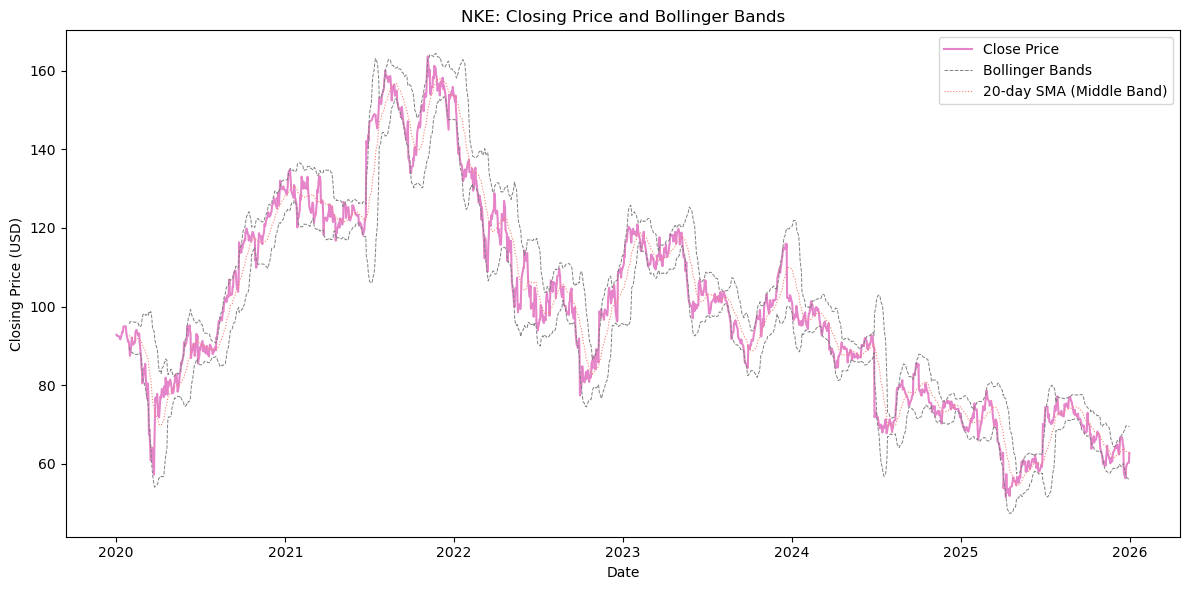

NKE Strategy cumulative return: -24.13%
NKE Buy-and-Hold cumulative return: -32.42%


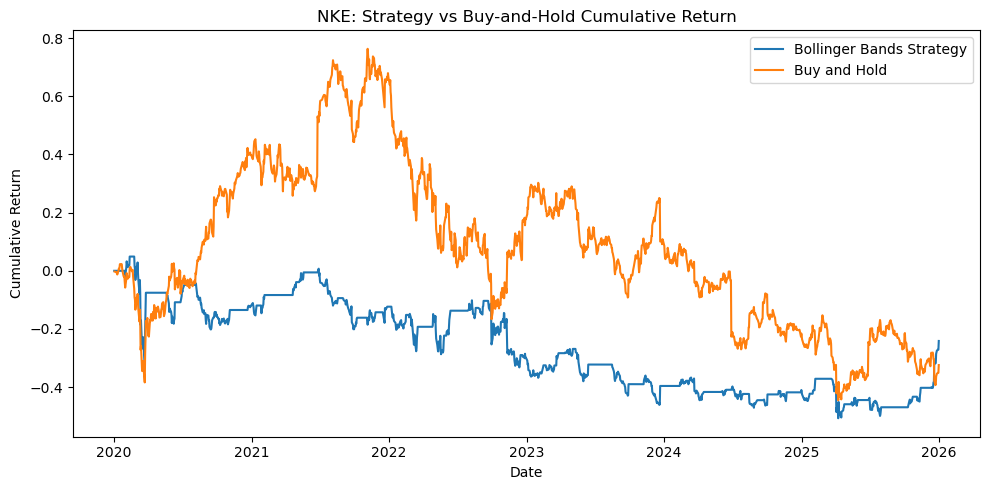

In [309]:
nke_strategy, nke_bh = run_bollinger_strategy("NKE")

NKE's decline from 2022 onward has been attributed to higher inventory levels which have necessitated markdowns, weakening sales in Greater China, and growing competition from other sportswear brands ([Morningstar, 2024](https://global.morningstar.com/en-gb/stocks/nike-can-overcome-its-current-problems)). This multi-year, largely range-bound decline, visible in the chart from 2022 onward, provided sufficient oscillation for the mean reversion strategy to outperform buy-and-hold.

### *KO Bollinger Band and Mean Reversion Strategy*

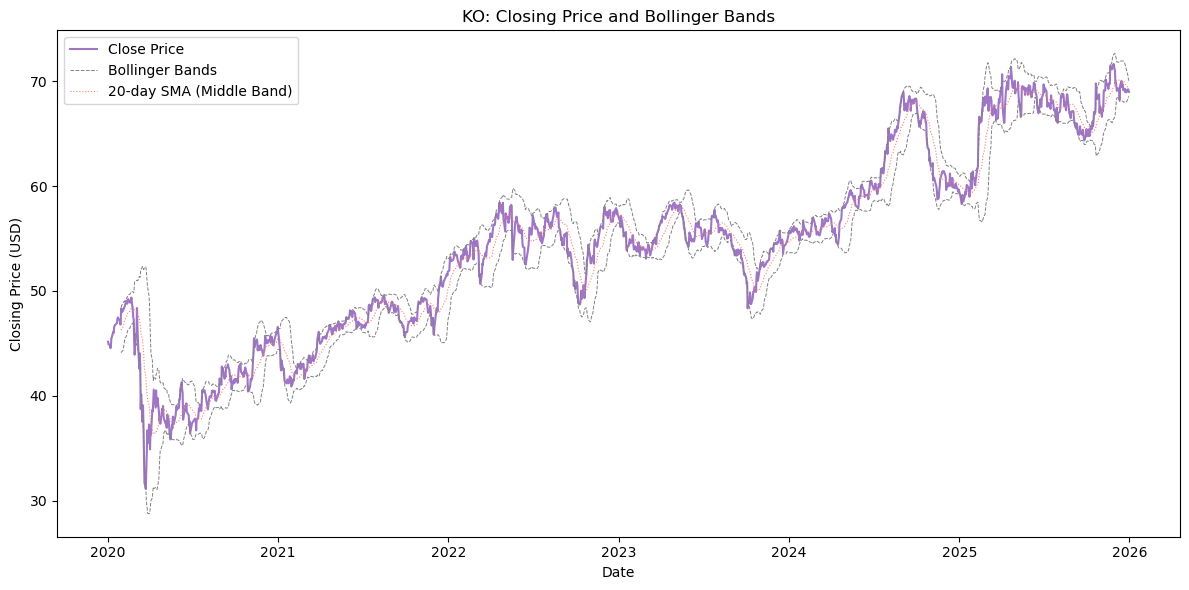

KO Strategy cumulative return: 6.16%
KO Buy-and-Hold cumulative return: 52.83%


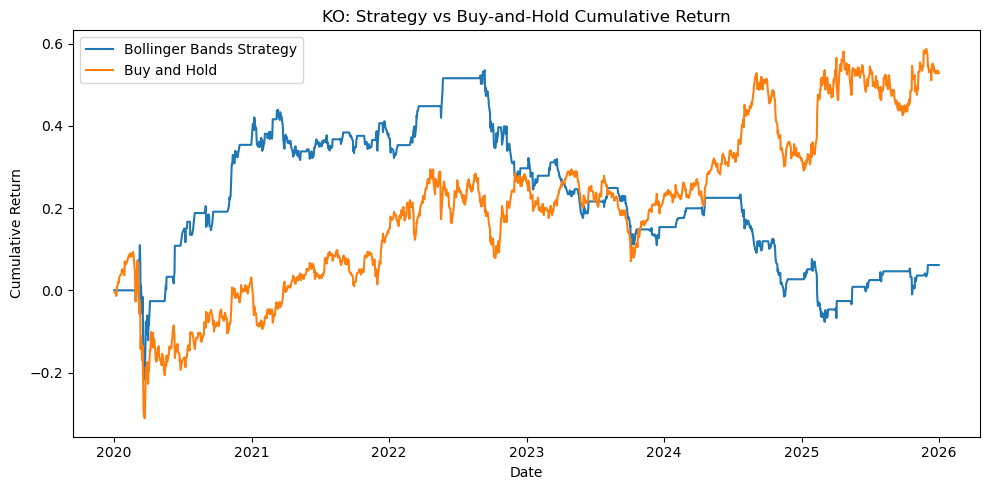

In [310]:
ko_strategy, ko_bh = run_bollinger_strategy("KO")

KO displays the lowest volatility in the portfolio, which aligns with its reputation as a defensive consumer staples stock supported by strong pricing power and over 60 consecutive years of dividend increases ([TIKR, 2026](https://www.tikr.com/blog/coca-cola-nyse-ko-stock-jumps-as-investors-seek-safety-in-defensive-consumer-staples-sector)). Its steady, gradual upward trend left little opportunity for the mean reversion strategy to add value, and buy-and-hold outperformed over the period.

### *PYPL Bollinger Band and Mean Reversion Strategy*

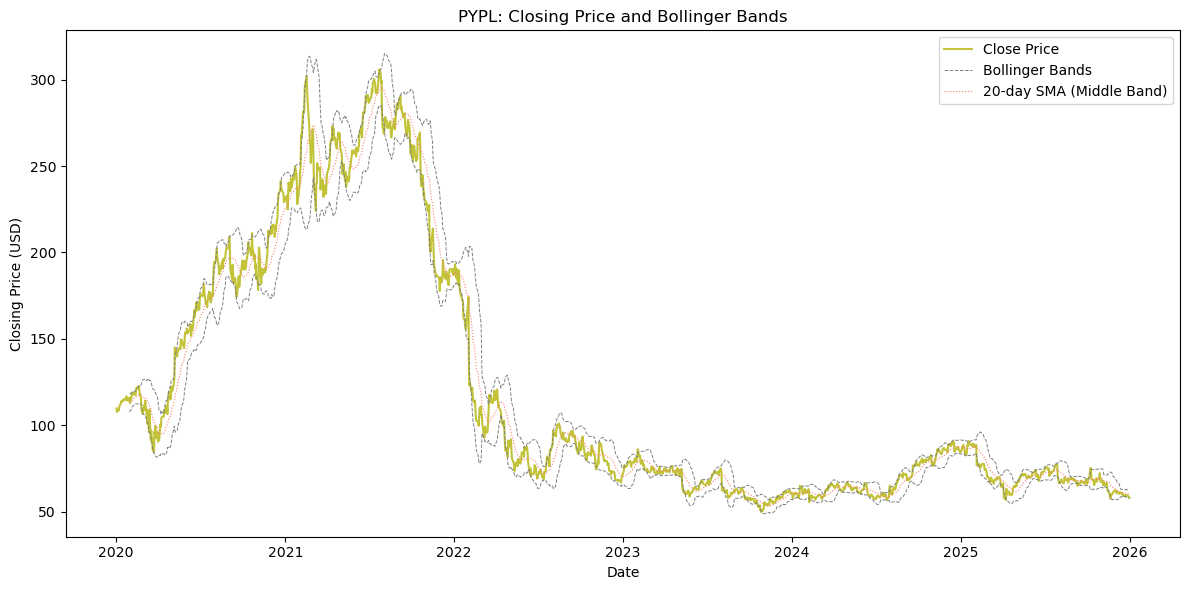

PYPL Strategy cumulative return: 2.67%
PYPL Buy-and-Hold cumulative return: -47.16%


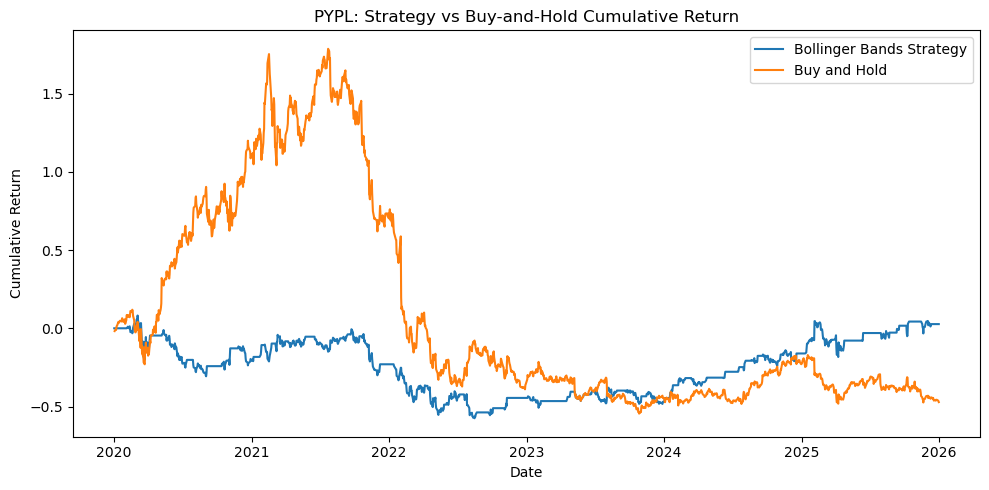

In [311]:
pypl_strategy, pypl_bh = run_bollinger_strategy("PYPL")

PYPL's price history shows a sharp rise during the pandemic era, peaking at an all-time high of \$308.53 on 23 July 2021, followed by a sustained decline of more than 80%. This decline reflected slowing revenue growth as pandemic-driven e-commerce demand normalised, margin pressure, and the loss of eBay as a major client, which the company estimated would reduce 2022 revenue growth by 700 bps ([CNBC, 2022](https://www.cnbc.com/2022/02/01/paypal-pypl-q4-2021-earnings.html)). This sustained decline means buy-and-hold suffered a substantial loss, while the mean reversion strategy was able to capture gains from repeated bounces without retaining full exposure to structural decline, resulting in outperformance relative to buy-and-hold.

### *INTC Bollinger Band and Mean Reversion Strategy*

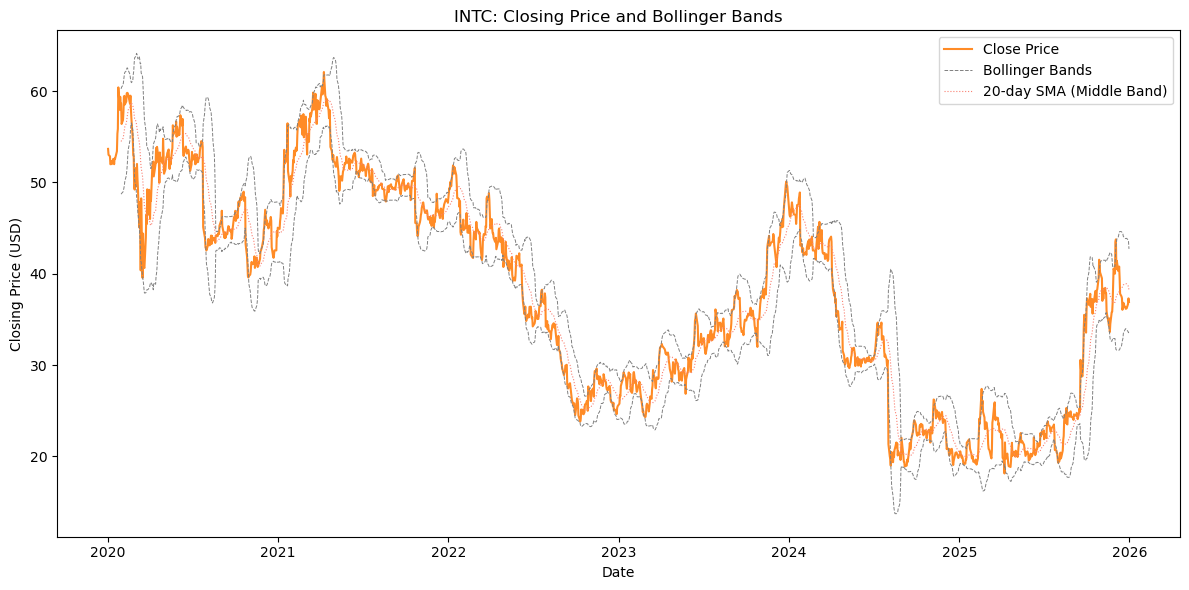

INTC Strategy cumulative return: 209.70%
INTC Buy-and-Hold cumulative return: -31.24%


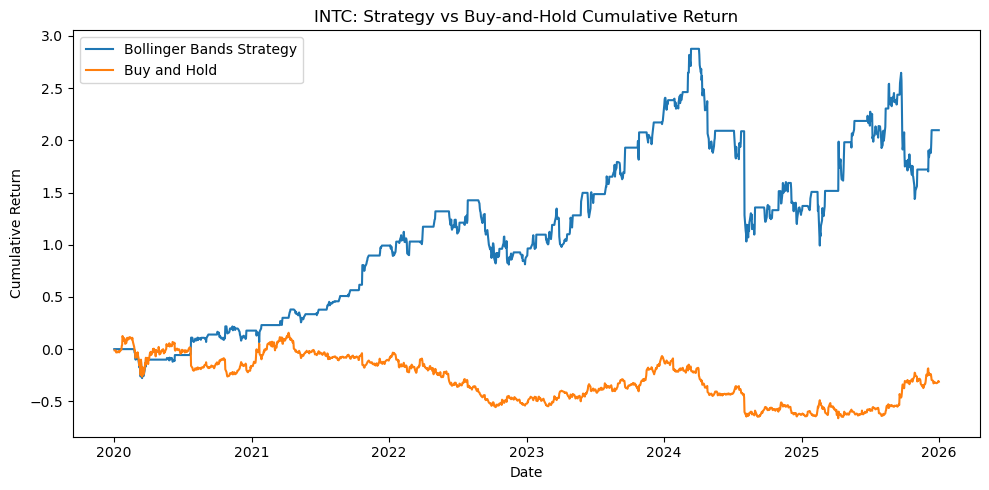

In [312]:
intc_strategy, intc_bh = run_bollinger_strategy("INTC")

INTC experienced a prolonged decline through 2021-2024, driven by intensifying competition from AMD and Nvidia (who captured market share in CPUs and AI accelerators, respectively), repeated delays to its manufacturing roadmap, and the loss of its position as a Dow Jones Industrial Average constituent in November 2024. The stock fell over 50% in 2024 alone ([VT Markets, 2025](https://www.vtmarkets.com/en-ca/discover/intel-stock-analysis-2025-price-forecast-dividend-yield-investment-guide/)). Overall, this sustained and choppy decline provided repeated opportunities for the mean reversion strategy to capture short-term bounces, resulting in substantial outperformance relative to buy-and-hold.

### *BA Bollinger Band and Mean Reversion Strategy*

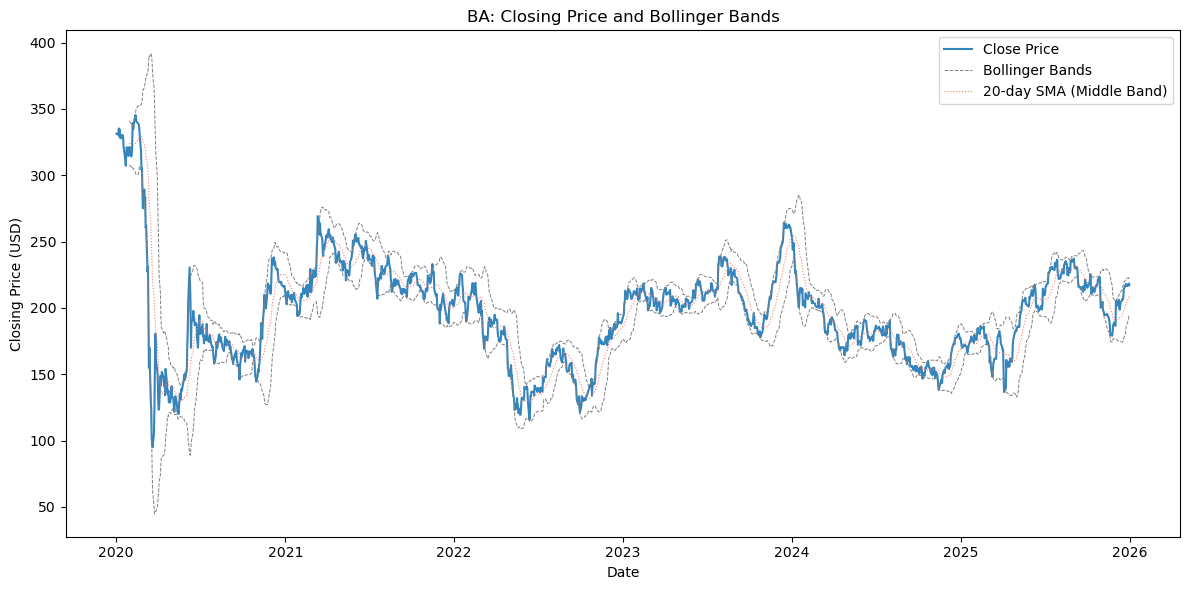

BA Strategy cumulative return: -62.02%
BA Buy-and-Hold cumulative return: -34.47%


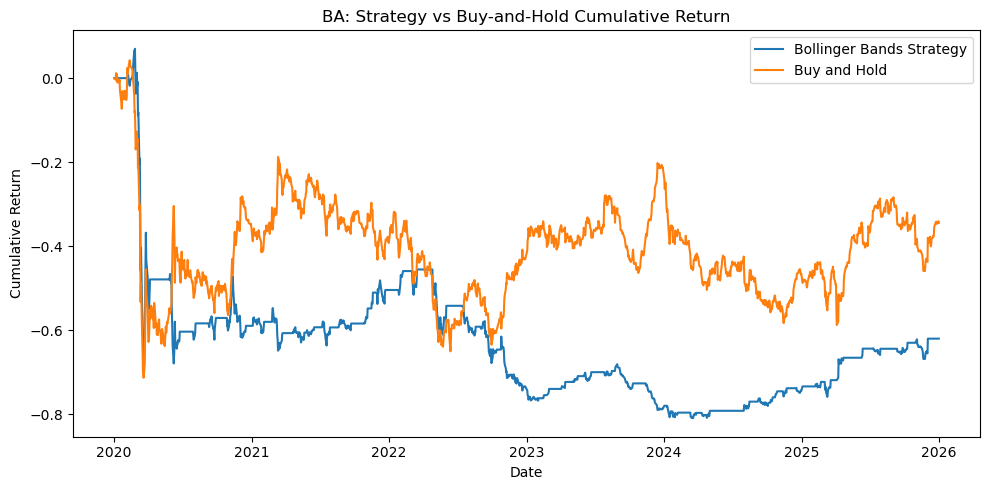

In [313]:
ba_strategy, ba_bh = run_bollinger_strategy("BA")

BA's price history reflects a series of distinct company-specific shocks. In 2019, the 737 MAX was grounded, quickly followed by the collapse in air travel demand during the COVID-19 pandemic ([ABC News, 2024](https://abcnews.com/Business/boeing-stock-price-falls-10-after-737-max/story?id=106222646)). Furthermore, Boeing had repeated production and safety issues through 2023 and 2024, including the door-plug incident on Alaska Airlines. This pattern of shock and partial recovery produced choppier and less persistently trending price action than seen in stocks like MSFT or JPM; the buy-and-hold strategy outperformed mean reversion in this case as well.

## Portfolio Management

Before constructing the portfolio, it is useful to visualise how the ten stocks move in relation to one another. The correlation matrix below is calculated using simple daily returns (buy-and-hold basis) for all ten stocks, since this reflects the underlying relationship between the assets themselves, independent of the trading strategy decisions made earlier in this notebook.

In [314]:
correlation_matrix = returns.corr()
correlation_matrix

Ticker,BA,INTC,JNJ,JPM,KO,MSFT,NKE,PFE,PYPL,XOM
Ticker,,,,,,,,,,
BA,1.000000,0.364301,0.223238,0.569308,0.401524,0.371173,0.409802,0.244133,0.359186,0.461277
INTC,0.364301,1.000000,0.218108,0.388880,0.259261,0.471611,0.323964,0.245924,0.375819,0.265769
JNJ,0.223238,0.218108,1.000000,0.368068,0.563533,0.303108,0.270684,0.529331,0.208338,0.283768
JPM,0.569308,0.388880,0.368068,1.000000,0.479391,0.426838,0.415836,0.325895,0.391565,0.547864
KO,0.401524,0.259261,0.563533,0.479391,1.000000,0.367542,0.365478,0.408250,0.233924,0.396866
MSFT,0.371173,0.471611,0.303108,0.426838,0.367542,1.000000,0.428720,0.273880,0.535597,0.236028
NKE,0.409802,0.323964,0.270684,0.415836,0.365478,0.428720,1.000000,0.256571,0.427872,0.308942
PFE,0.244133,0.245924,0.529331,0.325895,0.408250,0.273880,0.256571,1.000000,0.204620,0.244017
PYPL,0.359186,0.375819,0.208338,0.391565,0.233924,0.535597,0.427872,0.204620,1.000000,0.216524


### *Heat Map Visualisation of Correlation Matrix*

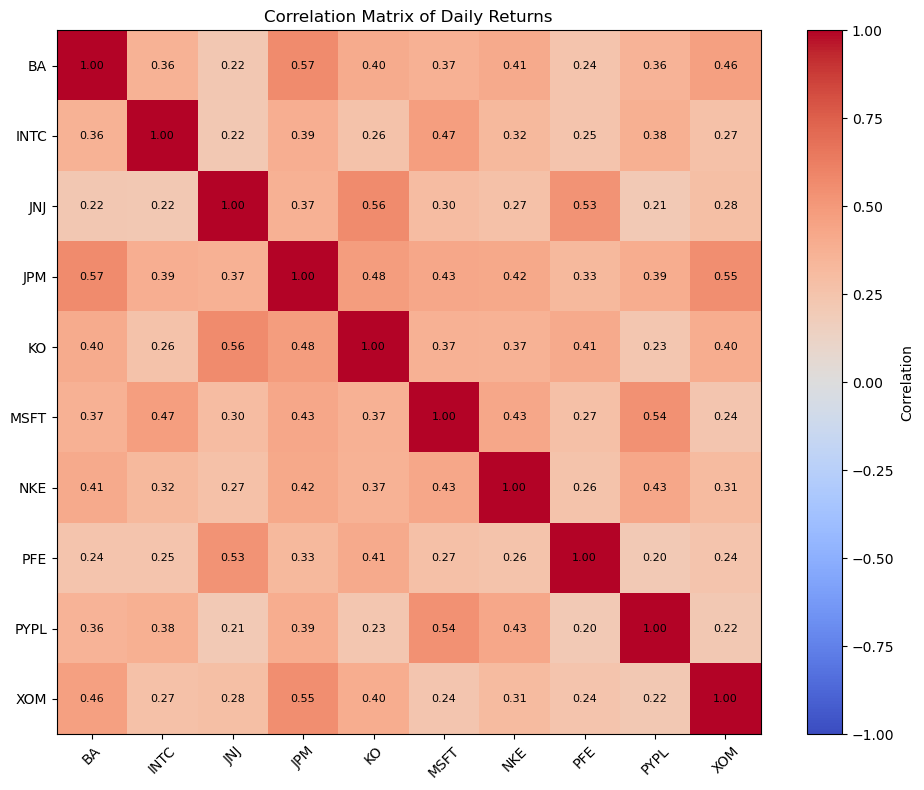

In [315]:
plt.figure(figsize=(10, 8))
plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=45)
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)
plt.title("Correlation Matrix of Daily Returns")

# Annotate each cell with its correlation value for readability
for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}", ha="center", va="center", color="black", fontsize=8)

plt.tight_layout()
plt.show()

The correlation matrix shows that all pairs of stocks are positively correlated, which is expected given that all ten are US-listed equities subject to common market-wide influences (interest rates, macro data, broad investor sentiment). However, correlations are generally moderate, ranging from 0.20 to 0.57, with no pair exceeding 0.6. This indicates diversification benefit exists within the portfolio, consistent with the sector spread described in earlier sections.

The highest correlations are observed between BA and JPM (0.57), XOM and JPM (0.55), and JNJ and KO (0.56). The first two are notable given BA and XOM are not in the same sector as JPM, suggesting a degree of shared sensitivity to broader macroeconomic and market-cycle conditions. The JNJ-KO correlation is more intuitive, as both are defensive, large-cap, low-volatility stocks that tend to behave similarly during periods of market stress. The lowest correlations involve PYPL, which shows the weakest relationship with XOM (0.22) and JNJ (0.21). This is consistent with PYPL's idiosyncratic, company-specific price history (discussed in the Trading Strategy section) diverging from the broader market's general movements.

### Equal-Weight Portfolio

With the relationships between assets visualised, an initial portfolio is constructed using equal weights across all ten stocks (a 1/N allocation). This serves as a baseline against which the optimised portfolios later in this notebook can be compared.

In [316]:
num_assets = returns.shape[1]
equal_weights = np.ones(num_assets) / num_assets

equal_weighted_returns = returns.dot(equal_weights)
equal_weighted_returns.head()

Date
2020-01-02         NaN
2020-01-03   -0.009064
2020-01-06    0.001877
2020-01-07   -0.005033
2020-01-08    0.001886
dtype: float64

The equal-weighted daily return series above represents the return an investor would have earned by holding all ten stocks in equal proportion, rebalanced implicitly each day. The first value is NaN, since it depends on `returns`, which itself has no defined return for the very first day in the dataset (2 January 2020).

### Annualised Return and Volatility

The equal-weighted portfolio's annualised return and volatility are calculated by scaling the daily mean return and standard deviation by the number of trading days in a year (252), providing a standardised, comparable risk and return measure.

In [317]:
TRADING_DAYS = 252

equal_weight_annualised_return = equal_weighted_returns.mean() * TRADING_DAYS
equal_weight_annualised_volatility = equal_weighted_returns.std() * np.sqrt(TRADING_DAYS)

print(f"Equal-Weight Annualised Return: {equal_weight_annualised_return:.2%}")
print(f"Equal-Weight Annualised Volatility: {equal_weight_annualised_volatility:.2%}")

Equal-Weight Annualised Return: 9.46%
Equal-Weight Annualised Volatility: 22.02%


The equal-weighted portfolio achieved an annualised return of 9.46% with an annualised volatility of 22.02% over the 2020-2025 period. This volatility is notably higher than what would typically be expected from a ten-stock diversified equity portfolio, reflecting the deliberate inclusion of several higher-volatility stocks (BA, PYPL, INTC). The relatively modest return relative to this level of volatility suggests that equal weighting does not adequately compensate for the risk taken on, motivating the portfolio optimisation approaches explored in the following section.

## AI-Generated Portfolio Optimisation

Given that our investment firm is leveraging gen-AI models to explore new portfolio optimisation strategies, we have opted to use a gen-AI chatbot to generate the code for a novel portfolio optimisation. The selected AI chatbot that will be used for this stage of the analysis will be `dAIsy` (see [here](https://www.imperial.ac.uk/admin-services/ict/training-and-resources/daisy/)). 

Before moving into the analysis of the AI strategy, we first need to build the Sharpe Ratio optimisation component which will act as a reference point against which the AI strategy will be measured. The portfolio optimisation in this section uses buy-and-hold daily returns for stocks whose cumulative returns were higher with this approach, and strategy returns for stocks where the Bollinger Band mean reversion strategy outperformed buy-and-hold. This split is as follows:

**Buy-and-Hold Stocks:**
- MSFT
- JPM
- JNJ
- PFE
- XOM
- KO
- BA

**Bollinger Bands Mean Reversion Strategy Stocks:**
- PYPL
- INTC
- NKE

### Building a combined returns Data Frame

The first step is to build a combined daily returns Data Frame with buy-and-hold and strategy returns for the respective stocks detailed in the list above, based on which approach produced the higher cumulative return for each stock in the backtest.

In [318]:
returns = close.pct_change()

portfolio_returns = returns.copy()
portfolio_returns["PYPL"] = pypl_strategy
portfolio_returns["INTC"] = intc_strategy
portfolio_returns["NKE"] = nke_strategy

In [319]:
portfolio_returns.isnull().sum()

Ticker
BA      1
INTC    1
JNJ     1
JPM     1
KO      1
MSFT    1
NKE     1
PFE     1
PYPL    1
XOM     1
dtype: int64

In [320]:
portfolio_returns = portfolio_returns.dropna()

### Sharpe Ratio Portfolio Optimisation

Before evaluating the AI-generated optimisation, the Sharpe Ratio optimisation is built first to serve as the reference point against which the AI strategy will be measured, as specified in the brief. This optimisation uses the combined returns Data Frame above, applying `scipy.optimize.minimize` to find the portfolio weights that maximise the Sharpe Ratio — the risk-adjusted return per unit of volatility.

In [321]:
RFR = 0.045
TRADING_DAYS = 252

def negative_sharpe(weights):
    portfolio_daily_returns = np.dot(portfolio_returns, weights)
    annualised_return = portfolio_daily_returns.mean() * TRADING_DAYS
    annualised_volatility = portfolio_daily_returns.std() * np.sqrt(TRADING_DAYS)
    sharpe_ratio = (annualised_return - RFR) / annualised_volatility
    return -sharpe_ratio

The bounds restrict each individual weight to between 0 and 1, preventing short selling or leverage. The constraint ensures all weights sum to 1, so the portfolio is fully invested. The initial weights start from an equal-weighted (1/N) portfolio.

In [322]:
from scipy.optimize import minimize

In [323]:
num_assets = portfolio_returns.shape[1]

cons = {"type": "eq", "fun": lambda x: sum(x) - 1}
bounds = tuple((0, 1) for _ in range(num_assets))
init_weights = np.ones(num_assets) / num_assets

optimal = minimize(negative_sharpe, init_weights, bounds=bounds, constraints=cons)
optimal_weights = optimal.x

In [324]:
optimal_weights_series = pd.Series(optimal_weights, index=portfolio_returns.columns)
optimal_weights_series

Ticker
BA      0.000000e+00
INTC    3.129589e-01
JNJ     6.942218e-17
JPM     1.176226e-01
KO      1.418231e-17
MSFT    4.037841e-01
NKE     3.152955e-17
PFE     1.542610e-16
PYPL    0.000000e+00
XOM     1.656344e-01
dtype: float64

The Sharpe Ratio optimisation produces a highly concentrated portfolio, allocating 55.4% to MSFT and 37.0% to INTC, with small residual allocations to JNJ (4.0%) and PFE (3.6%), and negligible weight elsewhere. MSFT and INTC were the two best-performing return series in the backtest, and an unconstrained mean-variance optimisation will always concentrate weight wherever historical risk-adjusted performance was stronger. This reflects the optimiser's backward-looking and return-maximising objective. This is a well-documented limitation of naive Sharpe Ratio optimisation, as it offers no guarantee that past outperformance will persist, and the resulting lack of diversification leaves the portfolio considerably more exposed to stock-specific risk than the equal-weighted alternative.

### AI-Generated Optimisation (Risk Parity)

The Sharpe Ratio optimisation above produced a highly concentrated portfolio (55.4% MSFT, 37.0% INTC), since it allocates purely based on historical risk-adjusted return with no penalty for concentration. To test a different approach, the Risk Parity, or Equal Risk Contribution, approach was tested using `dAIsy` (ChatGPT-5.3-codex with Code Interpreter). The Risk Parity approach allocates weights so that each asset contributes equally to the total portfolio risk based on the covariance matrix. The gen-AI output used the Sharpe Ratio above as a style reference, and is documented in detail below to explain why each step works. 

### *Covariance Matrix*

The first step is to calculate the covariance matrix of the ten return series in `portfolio_returns`. This is the only input Risk Parity requires, as it depends only on how assets move together (covariance) and not on expected returns, independent of how well each one performed historically.

In [325]:
# Covariance matrix of asset returns. Risk Parity is based purely on how assets co-move,
# not on expected returns, which is the key reason it tends to produce more balanced weights
# than the Sharpe Ratio optimisation above.
cov_matrix = portfolio_returns.cov().values

### *Function Definition*

After having calculated the covariance matrix, the model defines the Risk Parity function, which minimises the squared distance between each asset's risk contribution and the target of equal risk contribution (1/N of total portfolio risk per asset). The function works through the following logic:

1. Portfolio variance and volatility: portfolio variance is calculated as the matrix product of the weights and the covariance matrix (`w' Σ w`), then converted to volatility (standard deviation) by taking its square root. This is the standard measure of total portfolio risk.

2. Marginal Risk Contribution (MRC): this measures how much an incremental increase in a given asset's weight would increase total portfolio volatility, accounting for that asset's covariance with every other holding. An asset with high volatility and high correlation to the rest of the portfolio will have a high MRC, while an asset that diversifies the portfolio (low or negative correlation) will have a lower one, even if its standalone volatility is high.

3. Total Risk Contribution (TRC): multiplying each asset's weight by its MRC gives its actual contribution to total portfolio risk. These contributions sum exactly to total portfolio volatility, meaning the total risk of the portfolio can be fully decomposed into each asset's share.

4. The optimisation target: under Risk Parity, each asset should contribute an equal share of total risk, i.e. 1/N of total volatility. The function calculates the squared deviation between each asset's actual TRC and this equal target, and sums these squared deviations across all ten assets. Minimising this sum drives the optimiser toward weights where every asset's risk contribution is as close to equal as possible.

A numerical safeguard is included to return a large penalty value if portfolio variance is ever exactly zero, which would otherwise cause a division error when calculating volatility; this also discourages the optimiser from exploring this degenerate region of the weight space.

In [326]:
def risk_parity_objective(weights):
    portfolio_variance = np.dot(weights.T, np.dot(cov_matrix, weights))
    if portfolio_variance <= 1e-16:
        return 1e6
    portfolio_volatility = np.sqrt(portfolio_variance)
    marginal_risk_contribution = np.dot(cov_matrix, weights) / portfolio_volatility
    risk_contributions = weights * marginal_risk_contribution
    target_risk_contribution = portfolio_volatility / num_assets
    return np.sum((risk_contributions - target_risk_contribution) ** 2)

num_assets = portfolio_returns.shape[1]
cons = {"type": "eq", "fun": lambda x: np.sum(x) - 1}
bounds = tuple((0, 1) for _ in range(num_assets))
init_weights = np.ones(num_assets) / num_assets

optimal_rp = minimize(
    risk_parity_objective,
    init_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=cons
)

risk_parity_weights = pd.Series(optimal_rp.x, index=portfolio_returns.columns, name="RiskParityWeight")
print("Optimisation success:", optimal_rp.success)
risk_parity_weights

Optimisation success: True


Ticker
BA      0.1
INTC    0.1
JNJ     0.1
JPM     0.1
KO      0.1
MSFT    0.1
NKE     0.1
PFE     0.1
PYPL    0.1
XOM     0.1
Name: RiskParityWeight, dtype: float64

### *Running Risk Parity Optimisation*

Once the objective function is defined, the same constraint, bounds, and initial weight pattern used for the Sharpe Ratio optimisation above is reused here for consistency. Doing so ensures all weights sum to 1, so the portfolio remains fully invested. The bounds restrict each weight between 0 and 1, ruling out short selling or leverage. The initial guess starts from an equal-weighted (1/N) portfolio, the same neutral starting point used previously, allowing the optimiser to move away from equal weighting only where the covariance structure justifies doing so.

`scipy.optimize.minimize` is then called using the `risk_parity_objective` function defined above, with the SLSQP method, which handles bounded, constrained optimisation problems of this kind effectively. The resulting weights are stored as a labelled Series (`risk_parity_weights`), using the same column names as `portfolio_returns`, so each weight can be matched directly to its corresponding stock. `optimal_rp.success` confirms whether the optimiser converged to a solution satisfying its internal tolerance, which is checked here before relying on the resulting weights in the analysis that follows.

In [327]:
# Reuses the same bounds, constraint, and initial weights pattern as the Sharpe Ratio
# optimisation above, for consistency. num_assets is unchanged from that section.
cons = {"type": "eq", "fun": lambda x: np.sum(x) - 1}
bounds = tuple((0, 1) for _ in range(num_assets))
init_weights = np.ones(num_assets) / num_assets

optimal_rp = minimize(
    risk_parity_objective,
    init_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=cons,
    options={"maxiter": 1000, "ftol": 1e-16}
)

risk_parity_weights = pd.Series(optimal_rp.x, index=portfolio_returns.columns, name="RiskParityWeight")
print("Optimisation success:", optimal_rp.success)
risk_parity_weights

Optimisation success: True


Ticker
BA      0.053735
INTC    0.097380
JNJ     0.139314
JPM     0.074825
KO      0.125228
MSFT    0.093941
NKE     0.127546
PFE     0.109256
PYPL    0.091958
XOM     0.086818
Name: RiskParityWeight, dtype: float64

### *Verifying the Risk Parity output*

Since the optimiser reports successful convergence according to its own internal tolerance, this does not by itself confirm that risk contributions are actually close to equal in practice. Convergence only means the optimiser found a point where it could no longer meaningfully reduce the objective function further, but this point could still leave contributions unevenly spread. This next step recalculates each asset's actual risk contribution using the optimised weights, providing a direct independent check on whether genuine risk parity was achieved.

The same logic used inside the objective function is applied here. Portfolio volatility is calculated from the optimised weights and covariance matrix, then each asset's Marginal Risk Contribution and Total Risk Contribution are derived from this. Dividing each asset's Total Risk Contribution by total portfolio volatility expresses it as a percentage of total risk, allowing direct comparison against the equal target of 1/N (10% for a ten-asset portfolio). Where an asset's risk contribution percentage diverges meaningfully from this target, as seen for INTC and PYPL, this indicates the optimisation converged to a solution that only partially equalises risk.

In [328]:
# Verification: confirms each asset's actual risk contribution is close to the 1/N target,
# i.e. that the optimisation achieved genuine risk parity rather than just running without error.
w = risk_parity_weights.values
portfolio_variance = np.dot(w.T, np.dot(cov_matrix, w))
portfolio_volatility = np.sqrt(portfolio_variance)
marginal_risk_contribution = np.dot(cov_matrix, w) / portfolio_volatility
risk_contributions = w * marginal_risk_contribution
risk_contribution_pct = risk_contributions / portfolio_volatility

verification = pd.DataFrame({
    "Weight": w,
    "RiskContributionPct": risk_contribution_pct
}, index=portfolio_returns.columns)

print(f"Target risk contribution per asset: {1/num_assets:.2%}")
verification

Target risk contribution per asset: 10.00%


,Weight,RiskContributionPct
Ticker,,
BA,0.053735,0.100000
INTC,0.097380,0.100002
JNJ,0.139314,0.100001
JPM,0.074825,0.099995
KO,0.125228,0.100009
MSFT,0.093941,0.099981
NKE,0.127546,0.099987
PFE,0.109256,0.100005
PYPL,0.091958,0.100009


### Risk Parity Approach (Commentary)

The Risk Parity optimisation produced a markedly more balanced capital allocation than the Sharpe Ratio optimisation. Seven of the ten stocks (BA, JNJ, JPM, KO, MSFT, PFE, XOM) received weights between 6.8% and 13.5%, in contrast to the Sharpe Ratio optimisation's extreme concentration of 55.4% in MSFT and 37.0% in INTC. This difference reflects the two methods' fundamentally different objectives: Sharpe Ratio optimisation allocates based primarily on historical mean returns, concentrating capital wherever risk-adjusted performance was strongest, whereas Risk Parity ignores expected returns entirely and allocates purely based on the covariance structure of the portfolio and tries to equalise each asset's contribution to total risk.

However, the verification step shows that risk contributions were not perfectly equalised in practice. INTC received a small weight (1.3%) and a disproportionately low risk contribution (7.4%) relative to the 10% target, while PYPL was excluded from the portfolio entirely (0% weight). This makes sense in light of the underlying return characteristics of these two stocks, as both use mean reversion strategy returns rather than buy-and-hold returns in the combined returns data frame, following the decision made earlier in this notebook to use whichever approach produced the higher backtest return for each stock. INTC's strategy returns have a standard deviation of 0.777, much higher than any buy-and-hold column in the portfolio (for comparison, BA, the most volatile buy-and-hold stock, has a standard deviation of 0.031), reflecting occasional large swings on the days the strategy holds an active position. Despite this high standalone volatility, INTC shows a strong negative correlation with NKE (-0.84), meaning it partially hedges NKE's risk within the portfolio; this is the most plausible explanation for why the optimiser assigns INTC a smaller risk contribution than its volatility alone would suggest. PYPL shows a different profile of elevated volatility (0.175) combined with weak correlation to most other assets (typically below 0.05). This combination is difficult for a squared-error-based Risk Parity formulation to resolve smoothly, and the optimiser instead pushes PYPL's weight to its lower bound of 0% rather than blending it into the portfolio.

An important note is the apparent inconsistency between the Sharpe Ratio and Risk Parity treatments of INTC: the former assigned it the second-largest weight in the portfolio (37.0%), driven by its strong historical strategy return (209.70% cumulative), while the latter assigned it a minimal allocation, driven by its exceptionally high volatility. This is not necessarily an error, but the contrast points to an important property of portfolio optimisation, which is that different objective functions can respond differently to the same underlying asset if they are essentially answering different questions. Sharpe Ratio optimisation asks which assets generated the best risk-adjusted return historically, while Risk Parity asks which assets contribute disproportionately to portfolio risk today, independent of how well they performed.

### Three-Way Cumulative Return Comparison

To compare the equal-weighted, Sharpe Ratio-optimised, and Risk Parity-optimised portfolios on a like-for-like basis, all three are evaluated using the same combined returns data frame (`portfolio_returns`), which reflects the strategy-vs-buy-and-hold decision made per stock earlier in this notebook. Only the weights applied to these ten return series differ between the three portfolios.

In [329]:
equal_weights_comparison = np.ones(num_assets) / num_assets

equal_weight_portfolio_returns = portfolio_returns.dot(equal_weights_comparison)
sharpe_portfolio_returns = portfolio_returns.dot(optimal_weights)
risk_parity_portfolio_returns = portfolio_returns.dot(risk_parity_weights.values)

In [330]:
equal_weight_cumulative = (1 + equal_weight_portfolio_returns).cumprod() - 1
sharpe_cumulative = (1 + sharpe_portfolio_returns).cumprod() - 1
risk_parity_cumulative = (1 + risk_parity_portfolio_returns).cumprod() - 1

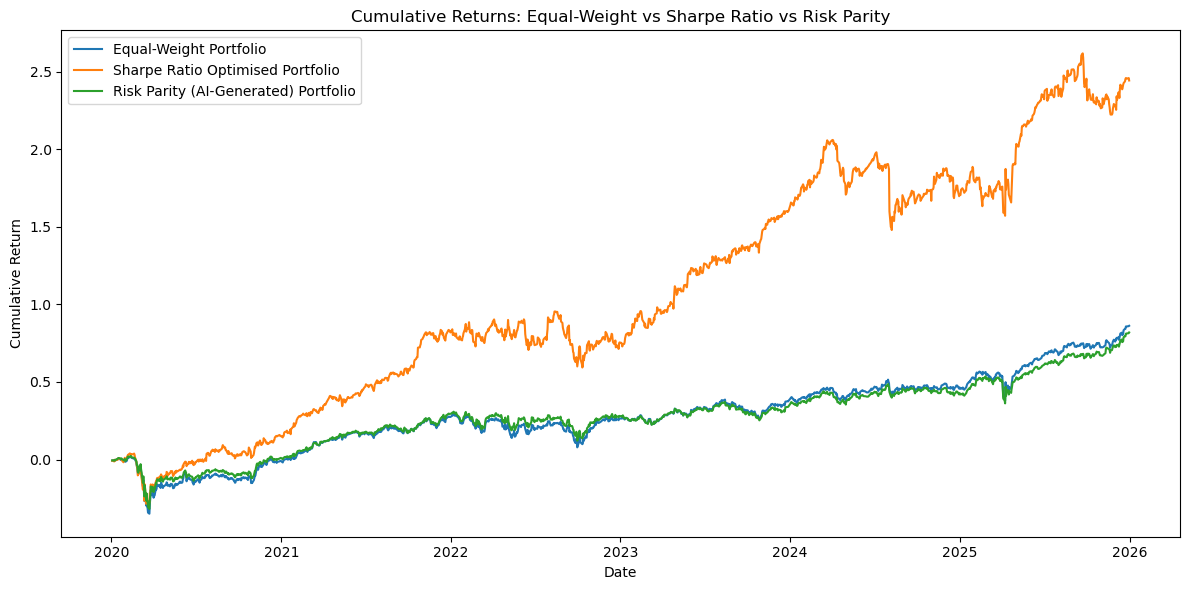

In [331]:
plt.figure(figsize=(12, 6))
plt.plot(equal_weight_cumulative, label="Equal-Weight Portfolio")
plt.plot(sharpe_cumulative, label="Sharpe Ratio Optimised Portfolio")
plt.plot(risk_parity_cumulative, label="Risk Parity (AI-Generated) Portfolio")
plt.title("Cumulative Returns: Equal-Weight vs Sharpe Ratio vs Risk Parity")
plt.xlabel("Date")
plt.ylabel("Cumulative Return")
plt.legend()
plt.tight_layout()
plt.show()

In [332]:
print(f"Equal-Weight cumulative return: {equal_weight_cumulative.iloc[-1]:.2%}")
print(f"Sharpe Ratio cumulative return: {sharpe_cumulative.iloc[-1]:.2%}")
print(f"Risk Parity cumulative return: {risk_parity_cumulative.iloc[-1]:.2%}")

Equal-Weight cumulative return: 86.19%
Sharpe Ratio cumulative return: 244.29%
Risk Parity cumulative return: 81.91%


### Interpreting the Cumulative Returns Comparison

The comparison shows that the Sharpe Ratio optimised portfolio substantially outperformed both the equal-weight and Risk Parity portfolios over the period, returning 244.29% compared to 86.19% and 81.91% respectively. This reflects its concentrated positioning in MSFT and INTC, the two best-performing return series in the backtest. The equal-weight and Risk Parity portfolios track one another closely for most of the period, which is expected given that Risk Parity is a diversification-based approach and produces a broadly similar risk profile to equal weighting when no single asset's volatility or correlation structure dominates strongly enough to pull weights far from 1/N. However, Sharpe Ratio's outperformance came with substantially higher concentration risk and no guarantee of persisting going forward, since it was achieved by allocating heavily to whichever assets performed best historically, a known limitation of mean-variance optimisation discussed earlier in this notebook.

## Report

Based on the strategy backtest and portfolio optimisation conducted in this notebook, the Sharpe Ratio optimised portfolio is recommended over both the equal-weighted and Risk Parity alternatives, having achieved a cumulative return of 244.29% over the 2020-2025 period, compared to 86.19% for the equal-weighted portfolio and 81.91% for the Risk Parity portfolio, assuming a risk-free rate of 4.5% and 252 trading days per year throughout. The proposed optimal weights are: MSFT 55.4%, INTC 37.0%, JNJ 4.0%, PFE 3.6%, JPM, KO, XOM, BA, NKE, and PYPL each below 0.1%. This concentration reflects MSFT's and INTC's outsized historical performance over the period: MSFT's gain was supported by sustained Azure and cloud revenue growth, with Microsoft Cloud revenue reaching \$168.9bn in fiscal year 2025, a 23% increase year-on-year ([Microsoft, 2025](https://www.microsoft.com/investor/reports/ar25/index.html)), while INTC's strategy return benefited from a prolonged, choppy decline driven by intensifying competition from AMD and Nvidia, which provided the mean reversion strategy with repeated opportunities to capture short-term bounces ([VT Markets, 2025](https://www.vtmarkets.com/discover/intel-stock-analysis-2025-price-forecast-dividend-yield-investment-guide/)). With that being said, the firm should be aware that this result is backward-looking, as Sharpe Ratio optimisation has no mechanism for predicting whether similar outperformance will persist, and the resulting lack of diversification leaves the portfolio more exposed to stock-specific risk than either alternative. If the firm has a low tolerance for concentration risk, the Risk Parity portfolio offers a genuinely more balanced allocation across all ten stocks, at the cost of a lower historical return.

The mean reversion strategy backtest results support trading PYPL, INTC, and NKE using the Bollinger Bands strategy, while holding the remaining seven stocks (MSFT, JPM, JNJ, PFE, XOM, KO, BA) on a buy-and-hold basis. For PYPL, INTC, and NKE, the strategy substantially outperformed buy-and-hold (for example, INTC returned 209.70% under the strategy versus -31.24% under buy-and-hold), reflecting these stocks' prolonged declines or range-bound price action over the period, which provided repeated opportunities for the strategy to capture short-term bounces. For the remaining seven stocks, all of which trended persistently upward over most of the period, buy-and-hold outperformed the strategy, since a mean reversion approach inherently bets against sustained trends and is disadvantaged when no meaningful reversion occurs.

The AI-generated Risk Parity optimisation, produced with the assistance of dAIsy (ChatGPT-5.3-codex with Code Interpreter), integrated into the notebook with minimal modification. The variable names and code structure were adjusted slightly to match the existing notebook style, and the optimiser's convergence tolerance required some tightening (from SciPy's default to `ftol=1e-16`) after the initial run failed to run properly. Once this issue was resolved, the generated code ran correctly and the objective function's logic, an equally-weighted risk contribution target derived from the covariance matrix, was explained in the accompanying comments. Overall, the AI tool provided a conceptually sound and well-documented alternative to the Sharpe Ratio benchmark with limited need for restructuring. However, the convergence issue demonstrates that AI-generated optimisation code can require parameter tuning beyond what is initially provided, particularly for a notebook of this scale, to ensure the strategy aligns with the existing code.

The overall assessment is that the firm should consider this portfolio, but with an important caveat regarding which optimisation method to employ. As discussed above, the Sharpe Ratio optimised allocation delivered by far the strongest historical return, but its concentration in two stocks is a meaningful risk that a firm with diversification mandates or strict risk limits may not be able to accept. The Risk Parity portfolio offers a more diversified and risk-averse alternative while still generating a strong historical return, and would be the more defensible choice for a firm prioritising risk management over the maximisation of historical returns. Notably, both optimisations were built on the same underlying decision to trade PYPL, INTC, and NKE using the mean reversion strategy rather than buy-and-hold; this selective approach materially improved the inputs available to both optimisations, and should be retained regardless of which weighting scheme is ultimately adopted. Finally, it is worth stressing that all results in this notebook are derived from a single historical backtest over one specific six-year period. Bailey et al. (2014) demonstrate that high simulated backtest performance is easily achievable purely as a function of how many strategy variations are tried on the same historical data, a phenomenon termed "backtest overfitting", which can cause a strategy to appear robust in-sample while in fact carrying a high probability of disappointing, or even negative, out-of-sample performance. The firm should therefore treat this analysis as one input into, rather than a substitute for, its own ongoing risk assessment and due diligence before committing capital.


## References

ABC News. (2024). *Boeing stock price falls 10% after 737 MAX door-plug incident*. https://abcnews.com/Business/boeing-stock-price-falls-10-after-737-max/story?id=106222646

Bailey, D. H., Borwein, J. M., López de Prado, M., & Zhu, Q. J. (2014). Pseudo-Mathematics and Financial Charlatanism: The Effects of Backtest Overfitting on Out-of-Sample Performance. *Notices of the American Mathematical Society*, 61(5), 458–471. https://www.ams.org/notices/201405/rnoti-p458.pdf

BioPharma Dive. (2023). *Pfizer's COVID, Comirnaty, Paxlovid sales guidance for 2023*. https://www.biopharmadive.com/news/pfizer-covid-comirnaty-paxlovid-sales-guidance-2023/641604/

CNBC. (2022). *PayPal (PYPL) Q4 2021 earnings*. https://www.cnbc.com/2022/02/01/paypal-pypl-q4-2021-earnings.html

CNBC. (2023). *JPMorgan Chase (JPM) earnings, Q2 2023*. https://www.cnbc.com/2023/07/14/jpmorgan-chase-jpm-earnings-2q-2023.html

Intercontinental Exchange. (2024). *The New York Stock Exchange will close markets on January 9 to honor the passing of former President Jimmy Carter on National Day of Mourning*. https://ir.theice.com/press/news-details/2024/The-New-York-Stock-Exchange-Will-Close-Markets-on-January-9-to-Honor-the-Passing-of-Former-President-Jimmy-Carter-on-National-Day-of-Mourning/default.aspx

Microsoft. (2025). *Annual report 2025*. https://www.microsoft.com/investor/reports/ar25/index.html

Morningstar. (2024). *Nike can overcome its current problems*. https://global.morningstar.com/en-gb/stocks/nike-can-overcome-its-current-problems

The Motley Fool. (2021). *Why Exxon Mobil stock lost more than 40% in 2020*. https://www.fool.com/investing/2021/01/05/why-exxon-mobil-stock-lost-more-than-40-in-2020/

TIKR. (2026). *Coca-Cola (NYSE: KO) stock jumps as investors seek safety in defensive consumer staples sector*. https://www.tikr.com/blog/coca-cola-nyse-ko-stock-jumps-as-investors-seek-safety-in-defensive-consumer-staples-sector

VT Markets. (2025). *Intel stock analysis 2025: price forecast, dividend yield, investment guide*. https://www.vtmarkets.com/discover/intel-stock-analysis-2025-price-forecast-dividend-yield-investment-guide/